 ## **Initialize**

In [10]:
import numpy as np
import random
import time
import matplotlib.pyplot as plt
import math
from math import gcd
from fractions import Fraction
import tracemalloc


 ## **Week 1**

 **Dirac Notation**

In [11]:
# Dirac Notation
myState=[
  (np.sqrt(0.1), '00'),
  (np.sqrt(0.4), '01') ,
  (-np.sqrt(0.5), '11' )
]

# Printing function
def PrettyPrintBinary(myState):
    """
        A function to print the given state in a pretty way
        Args:
            myState: vectorized state to print in dirac
    """
    string_to_print = "( "
    for state in myState:
        string_to_print += f"{state[0]} | {state[1]} > + "
    
    string_to_print = string_to_print[:-2]
    string_to_print += ")"
    print(string_to_print)

#PrettyPrintBinary(myState)

# Integer Printing function
def PrettyPrintInteger(myState):
    """
        A function to print the given state in a pretty way 
        using integers instead of binary
        Args:
            myState: vectorized state to print in dirac
    """
    string_to_print = "( "
    for state in myState:
        string_to_print += f"{state[0]} | {int(state[1], 2)} > + "
    
    string_to_print = string_to_print[:-2]
    string_to_print += ")"
    print(string_to_print)

#PrettyPrintInteger(myState)

myState2=[
   (np.sqrt(0.1)*1.j, '101'),
   (np.sqrt(0.5), '000') ,
   (-np.sqrt(0.4), '010' )]
PrettyPrintBinary(myState2)
PrettyPrintInteger(myState2)

def DiracToVec(myState):
    """
        A function to convert Dirac notation to vector notation
        Args:
            myState: Dirac state to convert to Vector
    """
    vec_size = len(myState[0][1])
    vec = np.zeros(2**(vec_size), dtype=complex)

    for element in myState:
        vec[int(element[1], 2)] = element[0]

    return list(vec)

print(DiracToVec(myState2))


def VecToDirac(myVec):
    """
        A function to convert Vector notation to Dirac notation
        Args:
            myVec: vectorized state to convert to Dirac
    """
    myState = []
    num_qubits = int(np.log2(len(myVec)))
    for i in range(len(myVec)):
        myState.append((myVec[i], format(i, f"0{num_qubits}b")))

    return myState

print(VecToDirac(DiracToVec(myState2)))




( 0.31622776601683794j | 101 > + 0.7071067811865476 | 000 > + -0.6324555320336759 | 010 > )
( 0.31622776601683794j | 5 > + 0.7071067811865476 | 0 > + -0.6324555320336759 | 2 > )
[np.complex128(0.7071067811865476+0j), np.complex128(0j), np.complex128(-0.6324555320336759+0j), np.complex128(0j), np.complex128(0j), np.complex128(0.31622776601683794j), np.complex128(0j), np.complex128(0j)]
[(np.complex128(0.7071067811865476+0j), '000'), (np.complex128(0j), '001'), (np.complex128(-0.6324555320336759+0j), '010'), (np.complex128(0j), '011'), (np.complex128(0j), '100'), (np.complex128(0.31622776601683794j), '101'), (np.complex128(0j), '110'), (np.complex128(0j), '111')]


 **Quantum Simulators**

In [12]:
#The three gates

hadamard_gate = (1/np.sqrt(2)) * np.array([[1, 1],
                                           [1, -1]])


cnot_gate = np.array([[1,0,0,0],
                      [0,1,0,0],
                      [0,0,0,1],
                      [0,0,1,0]])

def get_phase_gate(angle):
    """
        A function to get the phase gate of a given angle
        Args:
            angle: angle to use for the imaginary phase gate value
    """
    e_i = np.exp(1j*angle)
    return np.array([[1, 0],
                     [0, e_i]])


def apply_hadamard(wire, input_state):
    """
        A function to apply the hadamard gate to a given input state and a wire
        Args:
            wire: wire to apply this on
            input_state: The input state coming into the hadamard gate
    """

    new_state = []
    
    for amplitude, binary_rep in input_state:

        wire_bit = binary_rep[wire]

        state_0 = binary_rep[:wire] + "0" + binary_rep[wire+1:]
        state_1 = binary_rep[:wire] + "1" + binary_rep[wire+1:]

        wire_bit = int(wire_bit)
        gate_column = hadamard_gate[:, wire_bit]

        new_state.append((amplitude * gate_column[0], state_0))
        new_state.append((amplitude * gate_column[1], state_1))

        # Or I could also do this
        # if (wire_bit == "0"):
        #     new_state.append((amplitude / np.sqrt(2), state_0))
        #     new_state.append((amplitude / np.sqrt(2), state_1))

        # else:
        #     new_state.append((amplitude / np.sqrt(2), state_0))
        #     new_state.append((-amplitude / np.sqrt(2), state_1))

    return new_state

input_state=[
  (np.sqrt(0.1), '00'),
  (np.sqrt(0.4), '01') ,
  (-np.sqrt(0.5), '11' )
]

#print(apply_hadamard(0, input_state))


def apply_phase_gate(wire, theta, inputState):
    """
        A function to apply the phase gate to a given input state and a wire
        Args:
            wire: wire to apply this on
            input_state: The input state coming into the phase gate
    """
    new_state = []
    phase_gate = get_phase_gate(theta)
        
    for amplitude, binary_rep in inputState:

        wire_bit = int(binary_rep[wire])
        new_amplitude = amplitude * phase_gate[wire_bit, wire_bit]

        new_state.append((new_amplitude, binary_rep))

    return new_state

def apply_CNOT(controlWire, notWire, inputState):
    """
        A function to apply the phase gate to a given input state and a wire
        Args:
            controlWire: The control wire to use as reference
            notWire: The wire to flip using the control wire
            inputState: The input state coming into the cnot gate
    """
    new_state = []

    for amplitude, binary_rep in inputState:

        control_bit = binary_rep[controlWire]

        if control_bit == '1':

            target_index = notWire
            flipped_bit = '0' if binary_rep[target_index] == '1' else '1'
            new_binary = binary_rep[:target_index] + flipped_bit + binary_rep[target_index+1:]

        else:
            new_binary = binary_rep

        new_state.append((amplitude, new_binary))
        
    return new_state

    
        
def ReadInputString(myInput_lines):
    """
        A function to read from an input string
        Args:
            myInput_lines: The file containing the input
    """
    myInput=[]
    myInput_lines=myInput_lines.split('\n')
    myInput_lines = [ i for i in myInput_lines if i!='']
    numberOfWires=int(myInput_lines[0])
    for line in myInput_lines[1:]:
        myInput.append(line.split())
    return (numberOfWires,myInput)

def add_duplicate_state(input_state):
    """
        A function to remove duplicates and add them up in a state
        Args:
            input_state: The state in which duplicates should be removed
    """
    state_map = {}

    for amplitude, binary_rep in input_state:
        state_map[binary_rep] = state_map.get(binary_rep, 0) + amplitude

    new_list = []

    for binary_rep, amplitude in state_map.items():
        if not np.isclose(amplitude, 0):
            new_list.append((amplitude, binary_rep))

    return new_list

# numberOfWires,myInput=ReadInputString(open('example.circuit').read())

# print(numberOfWires)
# print(myInput)


def measure_state_S(input_state):
    """
        Collapse a state to a single basis state via measurement.
        Args:
            input_state: list of (amplitude, binary_rep) tuples
        Returns:
            binary_rep (str) of the measured outcome (has weighted probability)
    """
    binary_reps = [rep for _, rep in input_state]
    probs = [abs(amp)**2 for amp, _ in input_state]

    # Must normalize
    total = sum(probs)
    probs = [p / total for p in probs]

    outcome = random.choices(binary_reps, weights=probs, k=1)[0]

    # The outcome needs to be random with weighted probabilities
    return outcome

def measure_state_M(state_vector):
    """
        Collapse a state vector to a single basis state via measurement.
        Args:
            state_vector: numpy array of complex amplitudes
        Returns:
            integer index of the measured outcome
    """
    probs = np.abs(state_vector)**2
    total = np.sum(probs)
    probs = probs / total

    outcome = np.random.choice(len(state_vector), p=probs)
    return outcome



def simulatorS(myInput, input_state):
    """
        The quantum simulator S
        Args:
            myInput: The input read from a input file
            input_state: The initial state to modify
    """

    current_state = input_state

    for gate in myInput:

        if gate[0] == 'INITSTATE':
            continue

        if gate[0] == 'MEASURE':
            return measure_state_S(current_state)

        if gate[0] == 'H':
            wire = int(gate[1])
            current_state = apply_hadamard(wire, current_state)

        elif gate[0] == 'P':
            wire = int(gate[1])
            theta = float(gate[2])
            current_state = apply_phase_gate(wire, theta, current_state)

        elif gate[0] == 'CNOT':
            controlWire = int(gate[1])
            notWire = int(gate[2])
            current_state = apply_CNOT(
                controlWire,
                notWire,
                current_state
            )

        if gate[0] == 'xyModN':
            start, n, x, N = map(int, gate[1:5])
            current_state = apply_xyModN(start, n, x, N, current_state)
        elif gate[0] == 'CxyModN':
            ctrl, start, n, x, N = map(int, gate[1:6])
            current_state = apply_CxyModN(ctrl, start, n, x, N, current_state)

        current_state = add_duplicate_state(current_state)

    return current_state



# numberOfWires, myInput = ReadInputString(open('example.circuit').read())

# initial_state = [
#     (1, '0' * numberOfWires)
# ]

# new_state_1 = simulatorS(myInput, initial_state)

# print(new_state_1)
# PrettyPrintBinary(new_state_1)

numberOfWires, myInput = ReadInputString(open('rand.circuit').read())

initial_state = [
    (1, '0' * numberOfWires)
]

new_state_1 = simulatorS(myInput, initial_state)

print(new_state_1)
PrettyPrintBinary(new_state_1)



[(np.complex128(0.14565796004368065+0.11348294333323074j), '00000'), (np.complex128(-0.00017826157500451523+0.08005459383129264j), '00010'), (np.complex128(0.001474690001990256-0.036459032126468345j), '10000'), (np.complex128(-0.08205100536822746+0.015513990179495646j), '10010'), (np.complex128(0.043097550946832736-0.12184596055817097j), '00001'), (np.complex128(0.05035629868818656-0.007282489799443279j), '00011'), (np.complex128(-0.012673925486559965+0.005514371048822509j), '10001'), (np.complex128(0.016011739671690253+0.02259413933738235j), '10011'), (np.complex128(0.07232672559216355-0.02261927030390635j), '00100'), (np.complex128(0.05394795241192365+0.008954381028197886j), '00110'), (np.complex128(-0.17165615534648057+0.366922113805503j), '10100'), (np.complex128(-0.14693154505266529-0.04361461090635174j), '10110'), (np.complex128(-0.03444784817538661-0.042228210929983696j), '00101'), (np.complex128(0.0017934458673293414-0.026754015134267246j), '00111'), (np.complex128(0.2774713578

 **Simulator M**

( (0.14565796004368067+0.11348294333323074j) | 00000 > + (0.04309755094683274-0.12184596055817097j) | 00001 > + (-0.00017826157500453493+0.08005459383129264j) | 00010 > + (0.05035629868818658-0.007282489799443244j) | 00011 > + (0.07232672559216345-0.02261927030390632j) | 00100 > + (-0.034447848175386576-0.042228210929983676j) | 00101 > + (0.05394795241192359+0.008954381028197959j) | 00110 > + (0.00179344586732934-0.02675401513426728j) | 00111 > + (0.1346462884836885-0.1256031965657913j) | 01000 > + (-0.10409972085638472-0.06762381241864736j) | 01001 > + (0.01065232317344978+0.07094564243091282j) | 01010 > + (0.0315367895599324-0.03537779772012161j) | 01011 > + (0.00792047444919658+0.2978985122057254j) | 01100 > + (0.19608126814268645-0.058353449719806036j) | 01101 > + (-0.1130653010103075-0.022843082802562538j) | 01110 > + (0.025670653436356022+0.07563944999428011j) | 01111 > + (0.0014746900019902362-0.03645903212646829j) | 10000 > + (-0.012673925486559944+0.005514371048822493j) | 1000

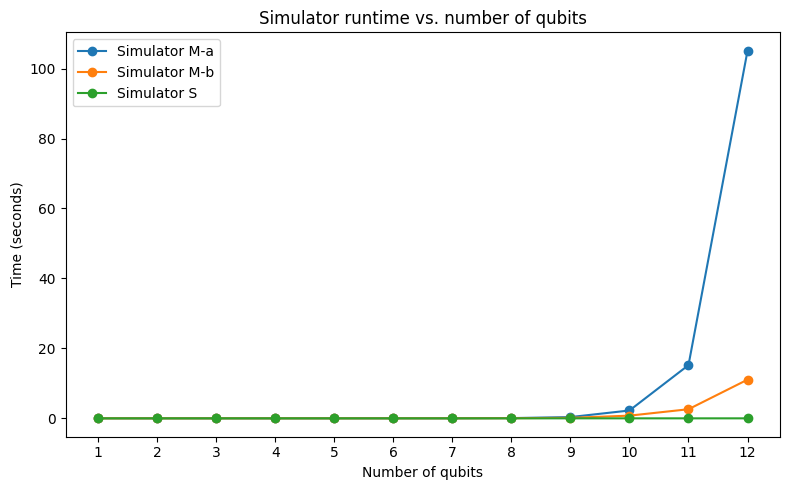

n= 1  M-a:     0.01 MB   M-b:     0.01 MB
n= 2  M-a:     0.01 MB   M-b:     0.01 MB
n= 3  M-a:     0.01 MB   M-b:     0.01 MB
n= 4  M-a:     0.03 MB   M-b:     0.02 MB
n= 5  M-a:     0.09 MB   M-b:     0.06 MB
n= 6  M-a:     0.32 MB   M-b:     0.22 MB
n= 7  M-a:     1.12 MB   M-b:     0.60 MB
n= 8  M-a:     3.68 MB   M-b:     1.59 MB
n= 9  M-a:    14.69 MB   M-b:     6.32 MB
n=10  M-a:    58.74 MB   M-b:    25.22 MB


In [13]:
def HadamardArray(i, k):
    I = np.eye(2)

    myMatrix = []

    for wire in range(k):
        if wire == i:
            myMatrix.append(hadamard_gate)
        else:
            myMatrix.append(I)

    return tensor_me(myMatrix)

def phaseArray(i, k, phase):

    I = np.eye(2)

    myMatrix = []

    phase_matrix = get_phase_gate(phase)

    for wire in range(k):
        if wire == i:
            myMatrix.append(phase_matrix)
        else:
            myMatrix.append(I)

    return tensor_me(myMatrix)


def CNOTArray(controlWire, otherWire, totalWires):
    size = 2 ** totalWires
    myMatrix = np.zeros((size, size))

    # Go through every possible input basis state
    for input_state in range(size):

        # Check whether the control qubit is 1. input state is in binary
        # python right shift does lsb (rightmost) but quantum are from the left
        # shift and get the rightmost bit
        control_bit = (input_state >> (totalWires - 1 - controlWire)) & 1

        output_state = input_state

        # If control is 1, flip the target qubit
        if control_bit == 1:
            output_state = input_state ^ (1 << (totalWires - 1 - otherWire))

        # Map this input basis state to the correct output basis state
        myMatrix[output_state][input_state] = 1

    return myMatrix

def tensor_me(list_of_matrices):
    product = list_of_matrices[0]
    for element in list_of_matrices[1:]:
        product = np.kron(product, element)

    return product


def simulatorM_a(myInput, input_state, number_of_wires):
    """
        The quantum simulator M-a
        Args:
            myInput: The input read from a input file
            input_state: The initial state to modify
            number_of_wires: The total number of wires in the simulaotor
    """
    measure = False

    U = np.eye(2 ** number_of_wires, dtype=complex)

    for gate in myInput:

        if gate[0] == 'INITSTATE':
            continue

        if gate[0] == 'MEASURE':
            measure = True
            continue
        
        if gate[0] == 'H':
            wire = int(gate[1])
            M = HadamardArray(wire, number_of_wires)

        elif gate[0] == 'P':
            wire = int(gate[1])
            theta = float(gate[2])
            M = phaseArray(wire, number_of_wires, theta)

        elif gate[0] == 'CNOT':
            controlWire = int(gate[1])
            notWire = int(gate[2])
            M = CNOTArray(
                controlWire,
                notWire,
                number_of_wires
            )

        if gate[0] == 'xyModN':
            start, n, x, N = map(int, gate[1:5])
            M = apply_xyModN(start, n, x, N, U)
        elif gate[0] == 'CxyModN':
            ctrl, start, n, x, N = map(int, gate[1:6])
            M = apply_CxyModN(ctrl, start, n, x, N, U)

        U = M @ U

    final_state = U @ input_state

    if measure:
        return measure_state_M(final_state)

    return final_state

num_wires_M, myInput_M = ReadInputString(open('rand.circuit').read())

initial_state_m = [
    (1, '0' * num_wires_M)
]

initial_state_m = DiracToVec(initial_state_m)

new_state_1_m = simulatorM_a(myInput_M, initial_state_m, num_wires_M)

#print(new_state_1_m)

new_state_1_m = VecToDirac(new_state_1_m)

PrettyPrintBinary(new_state_1_m)

_, rand_inp = ReadInputString(open('rand.circuit').read())

s_initial = [(1, '0' * num_wires_M)]
s_out = add_duplicate_state(simulatorS(rand_inp, s_initial))

m_out = simulatorM_a(rand_inp, DiracToVec(s_initial), num_wires_M)

s_mags = sorted([abs(a) for a, _ in s_out])
m_mags = sorted([abs(a) for a in m_out])

print("Simulator S vs M-a match on rand.circuit:",
      np.allclose(s_mags, m_mags))


def simulatorM_b(myInput, input_state, number_of_wires):
    """
        The quantum simulator M-b
        Args:
            myInput: The input read from a input file
            input_state: The initial state to modify
            number_of_wires: The total number of wires in the simulaotor
    """

    current_state = input_state

    for gate in myInput:

        if gate[0] == 'INITSTATE':
            continue

        if gate[0] == 'MEASURE':
            return measure_state_M(current_state)

        if gate[0] == 'H':
            wire = int(gate[1])
            current_state = HadamardArray(wire, number_of_wires) @ current_state

        elif gate[0] == 'P':
            wire = int(gate[1])
            theta = float(gate[2])
            current_state = phaseArray(wire, number_of_wires, theta) @ current_state

        elif gate[0] == 'CNOT':
            controlWire = int(gate[1])
            notWire = int(gate[2])
            current_state = CNOTArray(
                controlWire,
                notWire,
                number_of_wires
            ) @ current_state

        if gate[0] == 'xyModN':
            start, n, x, N = map(int, gate[1:5])
            current_state = apply_xyModN(start, n, x, N, current_state) @ current_state
        elif gate[0] == 'CxyModN':
            ctrl, start, n, x, N = map(int, gate[1:6])
            current_state = apply_CxyModN(ctrl, start, n, x, N, current_state) @ current_state


    return current_state

m_out_b = simulatorM_b(rand_inp, DiracToVec(s_initial), num_wires_M)
m_mags_b = sorted([abs(a) for a in m_out_b])

print("Simulator S vs M-b match on rand.circuit:",
      np.allclose(s_mags, m_mags_b))


def random_circuit(num_wires, num_gates):
    """Generate a random circuit as a list of gate tokens."""
    circuit = []
    for _ in range(num_gates):


        if num_wires == 1:
            choice = random.choice(['H', 'P'])
        else:
            choice = random.choice(['H', 'P', 'CNOT'])

        if choice == 'H':
            circuit.append(['H', str(random.randrange(num_wires))])
        elif choice == 'P':
            circuit.append(['P', str(random.randrange(num_wires)),
                            str(random.uniform(0, 2 * np.pi))])
        else:  # CNOT
            c = random.randrange(num_wires)
            t = random.randrange(num_wires)
            while t == c:
                t = random.randrange(num_wires)
            circuit.append(['CNOT', str(c), str(t)])
    return circuit


def benchmark(max_qubits, gates_per_qubit):
    """Benchmark simulators M-a and M-b for 1..max_qubits qubits."""
    qubit_counts = list(range(1, max_qubits + 1))
    times_a = []
    times_b = []
    times_c = []

    for n in qubit_counts:

        num_gates = gates_per_qubit * n
        circuit = random_circuit(n, num_gates)

        psi = np.zeros(2 ** n, dtype=complex)
        psi[0] = 1

        numberOfWires = 2 ** n
        initial_state = [
            (1, '0' * numberOfWires)
        ]

        inpit = VecToDirac(circuit)

        t0 = time.perf_counter()
        simulatorS(inpit, initial_state)
        t_c = (time.perf_counter() - t0)

        t0 = time.perf_counter()
        simulatorM_a(circuit, psi.copy(), n)
        t_a = (time.perf_counter() - t0)

        t0 = time.perf_counter()
        simulatorM_b(circuit, psi.copy(), n)
        t_b = (time.perf_counter() - t0)

        times_a.append(t_a)
        times_b.append(t_b)
        times_c.append(t_c)

    return qubit_counts, times_a, times_b, times_c

random.seed(42)
np.random.seed(42)

qubits, t_a, t_b, t_c = benchmark(
    max_qubits=12,
    gates_per_qubit=5
)


plt.figure(figsize=(8, 5))

plt.plot(qubits, t_a, 'o-', label='Simulator M-a')
plt.plot(qubits, t_b, 'o-', label='Simulator M-b')
plt.plot(qubits, t_c, 'o-', label='Simulator S')

plt.xlabel('Number of qubits')
plt.ylabel('Time (seconds)')

plt.title('Simulator runtime vs. number of qubits')
plt.xticks(qubits)

plt.legend()
plt.tight_layout()

plt.show()

for n in range(1, 11):
    circuit = random_circuit(n, 5 * n)
    psi = np.zeros(2**n, dtype=complex)
    psi[0] = 1

    tracemalloc.start()
    simulatorM_a(circuit, psi.copy(), n)
    _, peak_a = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    tracemalloc.start()
    simulatorM_b(circuit, psi.copy(), n)
    _, peak_b = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    print(f"n={n:2d}  M-a: {peak_a/1e6:8.2f} MB   M-b: {peak_b/1e6:8.2f} MB")




 **Testing and Inputs**

Simulator S result:
( (0.15409919900412572-0.039023142873475775j) | 00000 > + (-0.02131981307535495+0.08774787414090221j) | 00010 > + (-0.1480464106395854+0.08745635006745286j) | 10000 > + (0.11691184507936053+0.013808709741378308j) | 10010 > + (0.04895105577891031-0.03001851549580141j) | 00001 > + (-0.1116091892870344-0.23332812293116612j) | 00011 > + (-0.06328890454391892+0.25662035423302676j) | 10001 > + (-0.02667646151394929-0.004062838923814427j) | 10011 > + (-0.033901258348144725-0.009674003342578126j) | 00100 > + (-0.19592098529914306+0.009885177232733758j) | 00110 > + (0.21923132553221591-0.21304182634262642j) | 10100 > + (-0.1479391543721399-0.10481145122901085j) | 10110 > + (-0.016746063710111725-0.13026586952891356j) | 00101 > + (-0.09796097290238416+0.013475996833847481j) | 00111 > + (-0.048941996178234734-0.11635508158684055j) | 10101 > + (0.2231675743280913+0.05083463296709693j) | 10111 > + (-0.18082511268453239+0.01438104561772749j) | 01000 > + (0.0010329113421169653-0.0

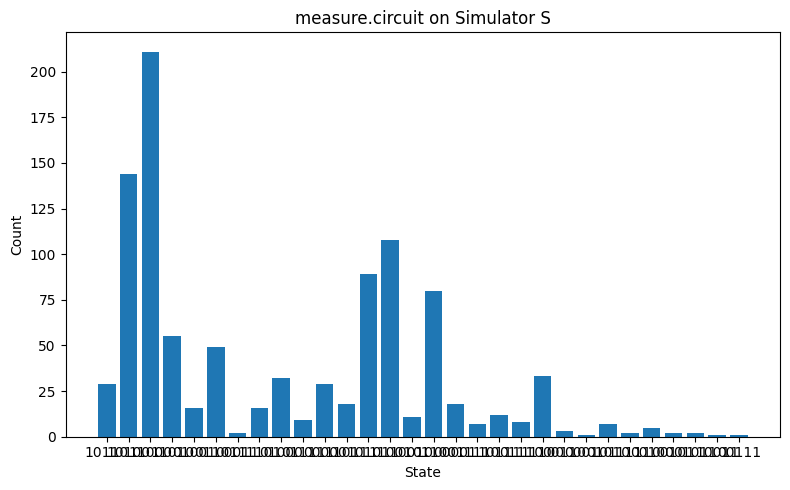

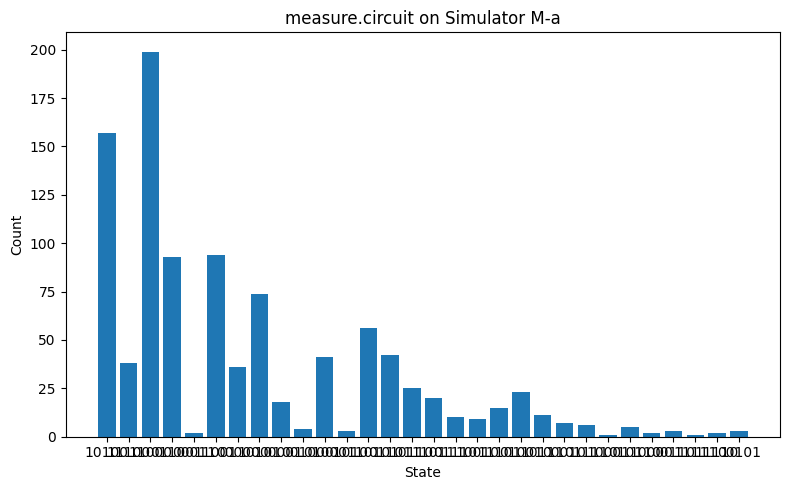

In [14]:
def read_state_file(filename, number_of_wires):
    amplitudes = []

    with open(filename, 'r') as f:
        for line in f:
            parts = line.split()

            real = float(parts[0])
            imaginary = float(parts[1])

            amplitudes.append(complex(real, imaginary))

    if len(amplitudes) != 2 ** number_of_wires:
        raise ValueError("Incorrect number of amplitudes")

    return np.array(amplitudes, dtype=complex)

def instantiate_state(myInput, number_of_wires):
    """Create the initial quantum state from INITSTATE."""

    state = np.zeros(2 ** number_of_wires, dtype=complex)
    state[0] = 1

    for gate in myInput:

        if gate[0] == 'INITSTATE':

            if gate[1] == 'BASIS':

                binary_state = gate[2].strip('|>')

                index = int(binary_state, 2)

                state = np.zeros(
                    2 ** number_of_wires,
                    dtype=complex
                )

                state[index] = 1

                return state

            # INITSTATE FILE myInputState.txt
            elif gate[1] == 'FILE':

                filename = gate[2]

                return read_state_file(
                    filename,
                    number_of_wires
                )

    return state

#Instantiate file S

numberOfWires, myInput = ReadInputString(
    open('input.circuit').read()
)

initial_state = instantiate_state(
    myInput,
    numberOfWires
)

initial_state = VecToDirac(initial_state)

result = simulatorS(
    myInput,
    initial_state
)

print("Simulator S result:")
PrettyPrintBinary(result)


# Instantiate file M_A

numberOfWires, myInput = ReadInputString(
    open('input.circuit').read()
)

initial_state = instantiate_state(
    myInput,
    numberOfWires
)

result = simulatorM_a(
    myInput,
    initial_state,
    numberOfWires
)

result = VecToDirac(result)

print("\nSimulator M-a result:")
PrettyPrintBinary(result)


# Measure circuit S

numberOfWires, myInput = ReadInputString(
    open('measure.circuit').read()
)

counts_S = {}

for i in range(1000):

    # Create default |000...0> state
    initial_state = [
        (1, '0' * numberOfWires)
    ]

    result = simulatorS(
        myInput,
        initial_state
    )

    # Count measurement result
    if result not in counts_S:
        counts_S[result] = 0

    counts_S[result] += 1


print("\nSimulator S measurement results:")

for state in sorted(counts_S):
    print(
        state,
        counts_S[state] / 1000
    )


# Measure circuit M_A

numberOfWires, myInput = ReadInputString(
    open('measure.circuit').read()
)

counts_M = {}

for i in range(1000):

    initial_state = instantiate_state(
        myInput,
        numberOfWires
    )

    result = simulatorM_a(
        myInput,
        initial_state,
        numberOfWires
    )

    if result not in counts_M:
        counts_M[result] = 0

    counts_M[result] += 1


print("\nSimulator M-a measurement results:")

for state in sorted(counts_M):
    print(
        format(state, f'0{numberOfWires}b'),
        counts_M[state] / 1000
    )

plt.figure(figsize=(8, 5))
plt.bar(list(counts_S.keys()), list(counts_S.values()))
plt.xlabel('State')
plt.ylabel('Count')
plt.title('measure.circuit on Simulator S')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
m_keys = [format(k, f'0{numberOfWires}b') for k in counts_M.keys()]
plt.bar(m_keys, list(counts_M.values()))
plt.xlabel('State')
plt.ylabel('Count')
plt.title('measure.circuit on Simulator M-a')
plt.tight_layout()
plt.show()


 **Non Atomic Gates**

In [15]:
def precompile(myInput):
    """
    Rewrite a circuit using non-atomic gates (NOT, Rz, CRz, CPHASE, SWAP)
    into one using only atomic gates (H, P, CNOT).
    Long-range CNOT is left as-is (native).
    """
    out = []

    for gate in myInput:
        name = gate[0].upper()

        # Pass-through
        if name in ('INITSTATE', 'MEASURE'):
            out.append(gate)
            continue

        if name == 'H':
            out.append(['H', gate[1]])
            continue

        if name == 'P':
            out.append(['P', gate[1], gate[2]])
            continue

        if name == 'CNOT':
            out.append(['CNOT', gate[1], gate[2]])
            continue

        if name == 'CXYMODN':
            out.append(gate)
            continue

        if name == 'NOT':
            wire = gate[1]
            out.append(['H', wire])
            out.append(['P', wire, str(np.pi)])
            out.append(['H', wire])
            continue

        if name == 'RZ':
            wire = gate[1]
            theta = float(gate[2])
            # Rz(theta) = P(theta) up to global phase
            out.append(['P', wire, str(theta)])
            continue

        if name == 'CRZ':
            c, t = gate[1], gate[2]
            theta = float(gate[3])
            half = theta / 2
            # CRz(c,t,theta) = P(t,theta/2) * CNOT(c,t) * P(t,-theta/2) * CNOT(c,t)
            out.append(['P', t, str(half)])
            out.append(['CNOT', c, t])
            out.append(['P', t, str(-half)])
            out.append(['CNOT', c, t])
            continue

        if name == 'CPHASE':
            c, t = gate[1], gate[2]
            theta = float(gate[3])
            half = theta / 2
            # CPHASE(c,t,theta) = P(c,theta/2) * P(t,theta/2) * CNOT(c,t) * P(t,-theta/2) * CNOT(c,t)
            out.append(['P', c, str(half)])
            out.append(['P', t, str(half)])
            out.append(['CNOT', c, t])
            out.append(['P', t, str(-half)])
            out.append(['CNOT', c, t])
            continue

        if name == 'SWAP':
            a, b = gate[1], gate[2]
            # SWAP(a,b) = CNOT(a,b) * CNOT(b,a) * CNOT(a,b)
            out.append(['CNOT', a, b])
            out.append(['CNOT', b, a])
            out.append(['CNOT', a, b])
            continue

        raise ValueError(f"Unknown gate: {gate}")

    return out

test_circuit = """
9
INITSTATE BASIS |000000000>
H 0
CPHASE 0 5 0.3
P 1 0.3
CNOT 4 7
SWAP 2 8
"""

numWires, myInput = ReadInputString(test_circuit)
compiled = precompile(myInput)

print(numWires)
for g in compiled:
    print(' '.join(g))

print("\n")

print("NOT:", precompile([['NOT', '0']]))
print("Rz:", precompile([['RZ', '0', '0.5']]))
print("CRz:", precompile([['CRZ', '0', '1', '0.5']]))
print("CPhase:", precompile([['CPHASE', '0', '1', '0.5']]))
print("Swap(2,5):", precompile([['SWAP', '2', '5']]))

# Run NOT on |1>
_, not_inp = ReadInputString("1\nINITSTATE BASIS |1>\nNOT 0")
not_compiled = precompile(not_inp)
not_result = simulatorS(not_compiled, [(1, '1')])
PrettyPrintBinary(not_result)


9
INITSTATE BASIS |000000000>
H 0
P 0 0.15
P 5 0.15
CNOT 0 5
P 5 -0.15
CNOT 0 5
P 1 0.3
CNOT 4 7
CNOT 2 8
CNOT 8 2
CNOT 2 8


NOT: [['H', '0'], ['P', '0', '3.141592653589793'], ['H', '0']]
Rz: [['P', '0', '0.5']]
CRz: [['P', '1', '0.25'], ['CNOT', '0', '1'], ['P', '1', '-0.25'], ['CNOT', '0', '1']]
CPhase: [['P', '0', '0.25'], ['P', '1', '0.25'], ['CNOT', '0', '1'], ['P', '1', '-0.25'], ['CNOT', '0', '1']]
Swap(2,5): [['CNOT', '2', '5'], ['CNOT', '5', '2'], ['CNOT', '2', '5']]
( (0.9999999999999998-6.123233995736765e-17j) | 0 > )


 ## **Week 2**

 **Phase estimation**

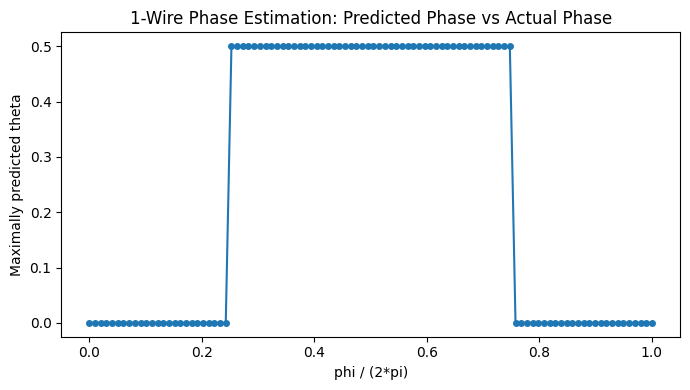

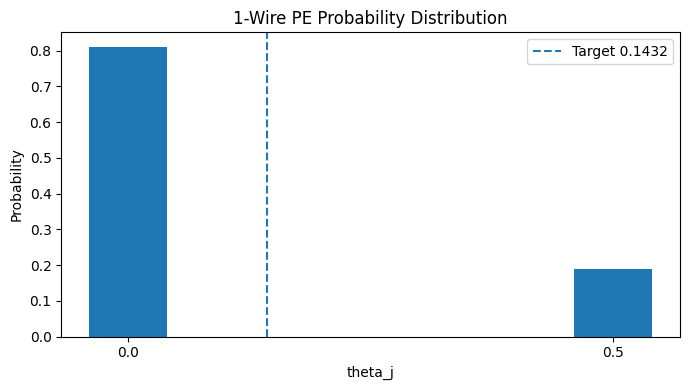

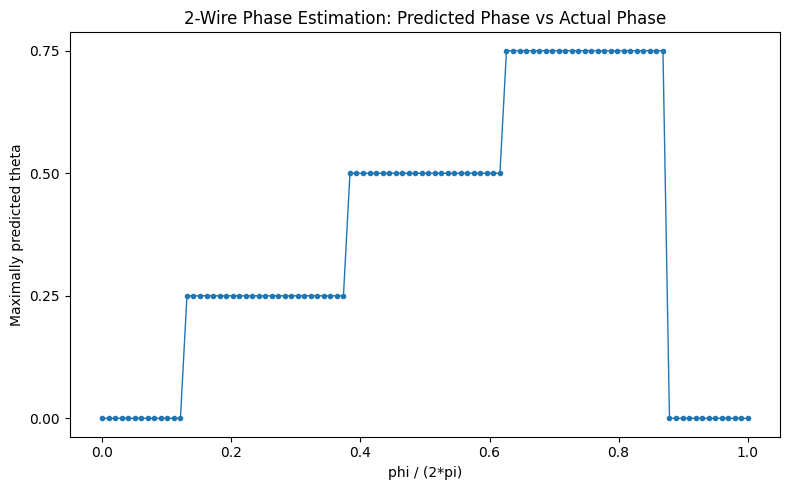

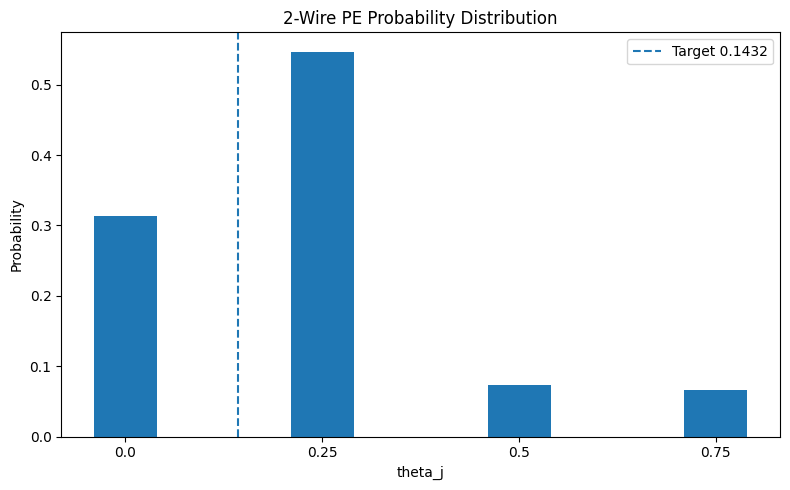

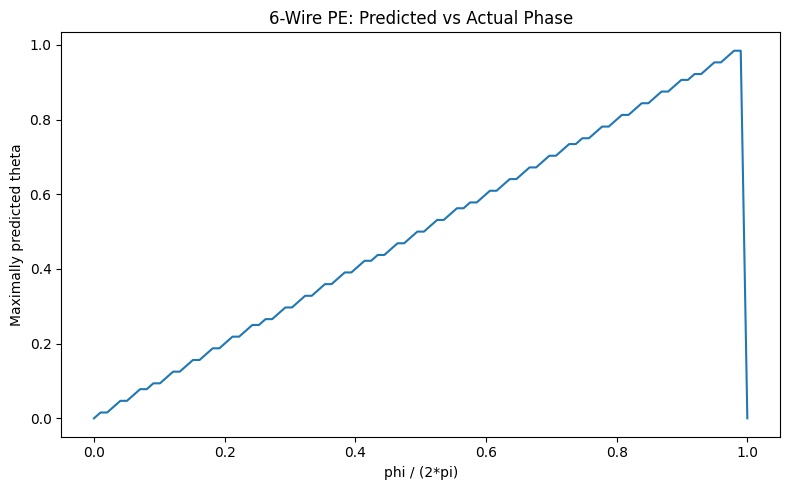

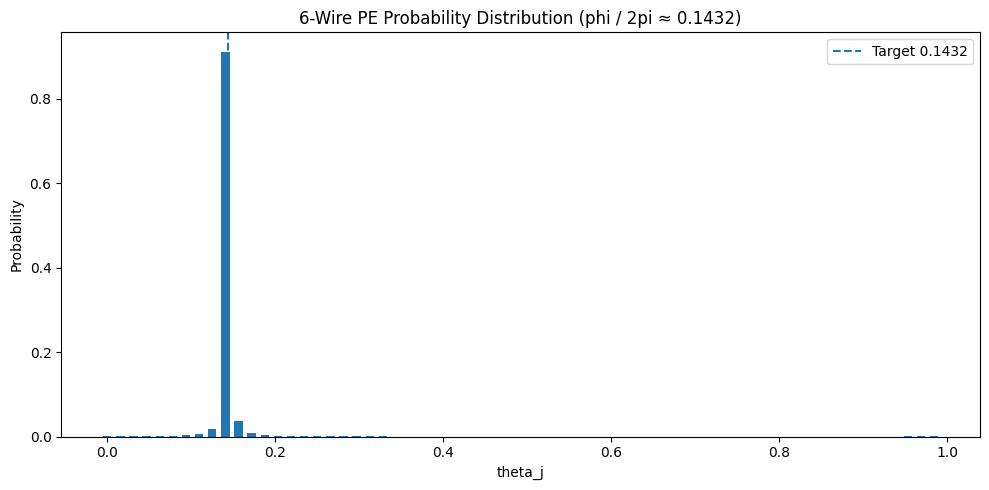

Circuit slow
7
INITSTATE BASIS |0000001>
H 0
H 1
H 2
H 3
H 4
H 5
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 0 6 0.9
CPHASE 1 6 0.9
CPHASE 1 6 0.9
CPHASE 1 6 0.9
CPHASE 1 6 0.9
CPHASE 1 6 0.9
CPHASE 1 6 0.9
CPHASE 1 6 0.9
CPHASE 1 6 0.9
CPHASE 1 6 0.9
CPHASE 1 6 0.9
CPHASE 1 6 0.9
CPHASE 1 6 0.9
CPHASE 1 6 0.9
CPHASE 1 6 0.9
CPHASE 1 6 0.9
CPHASE 1 6 0.9
CPHASE 2 6 0.9
CPHASE 2 6 0.9
CPHASE 2 6 0.9
CPHASE 2 6 0.9
CPHASE 2 6 0.9
CPHASE 2 6 0.9
CPHASE 2 6 0.9
CPHASE 2 6 0.9
CPHASE 3 6 0.9
CPHASE 3 6 0.9
CPHASE 3 6 0.9
CPHASE 3 6 0.9
CPHASE 4 6 0.9
CPHASE 4 6 0.9
CPHAS

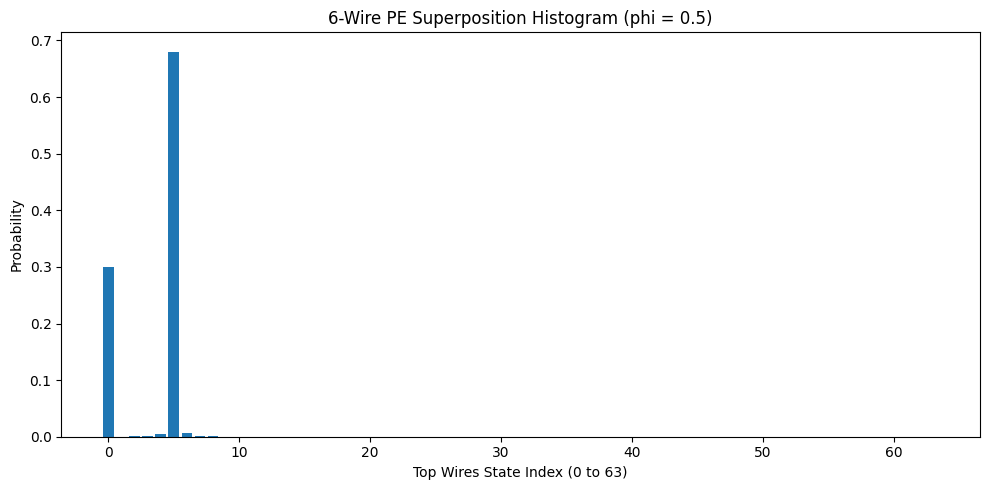

7
INITSTATE BASIS |0000001>
H 0
H 1
H 2
H 3
H 4
H 5
CPHASE 0 6 3.4336293856408275
CPHASE 1 6 1.7168146928204138
CPHASE 2 6 4.0
CPHASE 3 6 2.0
CPHASE 4 6 1.0
CPHASE 5 6 0.5
7
INITSTATE BASIS |0000001>
H 0
H 1
H 2
H 3
H 4
H 5
CNOT 0 6
CPHASE 0 6 1.0471975511965976
CNOT 0 6
CPHASE 0 6 1.0471975511965976
CNOT 0 6
CPHASE 0 6 1.0471975511965976
CNOT 0 6
CPHASE 0 6 1.0471975511965976
CNOT 0 6
CPHASE 0 6 1.0471975511965976
CNOT 0 6
CPHASE 0 6 1.0471975511965976
CNOT 0 6
CPHASE 0 6 1.0471975511965976
CNOT 0 6
CPHASE 0 6 1.0471975511965976
CNOT 0 6
CPHASE 0 6 1.0471975511965976
CNOT 0 6
CPHASE 0 6 1.0471975511965976
CNOT 0 6
CPHASE 0 6 1.0471975511965976
CNOT 0 6
CPHASE 0 6 1.0471975511965976
CNOT 0 6
CPHASE 0 6 1.0471975511965976
CNOT 0 6
CPHASE 0 6 1.0471975511965976
CNOT 0 6
CPHASE 0 6 1.0471975511965976
CNOT 0 6
CPHASE 0 6 1.0471975511965976
CNOT 0 6
CPHASE 0 6 1.0471975511965976
CNOT 0 6
CPHASE 0 6 1.0471975511965976
CNOT 0 6
CPHASE 0 6 1.0471975511965976
CNOT 0 6
CPHASE 0 6 1.0471975511965

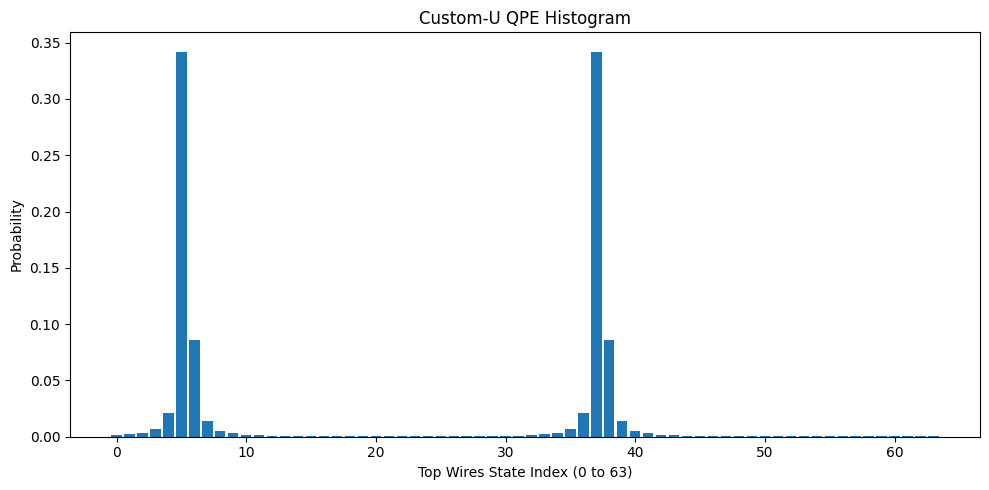

In [16]:

def run_phase_estimation_1qubit(phi):
    """
    One counting wire and one target wire.

    The target starts in |1>, which is an eigenstate of
    P(phi) with eigenvalue exp(i * phi).

    Possible phase estimates:
        0    -> |0>
        1/2  -> |1>
    """

    circuit_str = f"""2
INITSTATE BASIS |01>
H 0
CPHASE 0 1 {phi}
H 0
"""

    num_wires, raw_input = ReadInputString(circuit_str)
    compiled_circuit = precompile(raw_input)

    # Initial state is |01>
    init_vec = np.zeros(2**num_wires, dtype=complex)
    init_vec[1] = 1.0

    final_vec = simulatorM_a(
        compiled_circuit,
        init_vec,
        num_wires
    )

    probs = np.abs(final_vec) ** 2

    # Wire 0 is the counting wire.
    #
    # wire 0 = 0:
    #   |00> and |01>
    #
    # wire 0 = 1:
    #   |10> and |11>
    prob_0 = probs[0] + probs[1]
    prob_1 = probs[2] + probs[3]

    return {
        0.0: prob_0,
        0.5: prob_1
    }


# 100 evenly chosen values between 0 and 2*pi
phi_vals = np.linspace(0, 2 * np.pi, 100)
x_vals_1 = phi_vals / (2 * np.pi)

max_theta_1 = []

for phi in phi_vals:
    probability_distribution = run_phase_estimation_1qubit(phi)

    # The phase estimate with the largest probability
    best_theta = max(
        probability_distribution,
        key=probability_distribution.get
    )

    max_theta_1.append(best_theta)


# Plot predicted phase versus actual phase
plt.figure(figsize=(7, 4))
plt.plot(x_vals_1, max_theta_1, 'o-', markersize=4)
plt.xlabel('phi / (2*pi)')
plt.ylabel('Maximally predicted theta')
plt.title('1-Wire Phase Estimation: Predicted Phase vs Actual Phase')
plt.tight_layout()
plt.show()


# Probability histogram for the required value
target_phase_fraction = 0.1432394487827058
target_phi = target_phase_fraction * 2 * np.pi

p_dist_1 = run_phase_estimation_1qubit(target_phi)

plt.figure(figsize=(7, 4))

plt.bar(
    list(p_dist_1.keys()),
    list(p_dist_1.values()),
    width=0.08
)

plt.axvline(
    x=target_phase_fraction,
    linestyle='--',
    label='Target 0.1432'
)

plt.xlabel('theta_j')
plt.ylabel('Probability')
plt.title('1-Wire PE Probability Distribution')
plt.xticks([0.0, 0.5])
plt.legend()
plt.tight_layout()
plt.show()


# Helper: Inverse QFT for Phase Estimation

def generate_phase_estimation_iqft(num_top_wires):
    """
    Generates the inverse-QFT portion needed by phase estimation.

    The phase-estimation wires are ordered:
        wire 0 = most significant phase bit
        wire n-1 = least significant phase bit

    The final SWAPs perform the required bit reversal.
    """

    lines = []

    # Inverse QFT:
    # H on each wire followed by the required negative
    # controlled phase rotations.
    for target in range(num_top_wires):
        lines.append(f"H {target}")

        for control in range(target + 1, num_top_wires):
            distance = control - target
            angle = -np.pi / (2 ** distance)

            lines.append(
                f"CPHASE {target} {control} {angle}"
            )

    # Reverse the order of the phase bits.
    for i in range(num_top_wires // 2):
        lines.append(
            f"SWAP {i} {num_top_wires - 1 - i}"
        )

    return lines


# 2-Wire Phase Estimation

def run_phase_estimation_2qubit(phi):
    """
    Two counting wires and one target wire.

    Counting wires:
        wire 0 = most significant bit
        wire 1 = least significant bit

    Target:
        wire 2 = |1>

    The assignment constructs:
        wire 1 -> U
        wire 0 -> U^2

    Since U = P(phi), U^2 can simply be two P(phi) gates.
    """

    circuit_str = f"""3
INITSTATE BASIS |001>
H 0
H 1

CPHASE 1 2 {phi}

CPHASE 0 2 {phi}
CPHASE 0 2 {phi}

H 0
CPHASE 0 1 {-np.pi / 2}
H 1
SWAP 0 1
"""

    num_wires, raw_input = ReadInputString(circuit_str)
    compiled_circuit = precompile(raw_input)

    # Initial state is |001>
    init_vec = np.zeros(2**num_wires, dtype=complex)
    init_vec[1] = 1.0

    final_vec = simulatorM_a(
        compiled_circuit,
        init_vec,
        num_wires
    )

    probs = np.abs(final_vec) ** 2

    # There are four possible values for two phase bits:
    #
    # 00 -> 0
    # 01 -> 1/4
    # 10 -> 1/2
    # 11 -> 3/4
    #
    # The target wire is the last wire, so states that differ
    # only in the target wire are combined.
    theta_dist = {
        0.00: 0.0,
        0.25: 0.0,
        0.50: 0.0,
        0.75: 0.0
    }

    for idx, probability in enumerate(probs):
        counting_state = idx >> 1

        theta = counting_state / 4.0

        theta_dist[theta] += probability

    return theta_dist


# 100 evenly chosen values between 0 and 2*pi
phi_vals = np.linspace(0, 2 * np.pi, 100)
x_vals_2 = phi_vals / (2 * np.pi)

max_theta_2 = []

for phi in phi_vals:
    probability_distribution = run_phase_estimation_2qubit(phi)

    best_theta = max(
        probability_distribution,
        key=probability_distribution.get
    )

    max_theta_2.append(best_theta)


# Plot predicted phase versus actual phase
plt.figure(figsize=(8, 5))
plt.plot(
    x_vals_2,
    max_theta_2,
    'o-',
    markersize=3,
    linewidth=1
)

plt.xlabel('phi / (2*pi)')
plt.ylabel('Maximally predicted theta')
plt.title('2-Wire Phase Estimation: Predicted Phase vs Actual Phase')
plt.yticks([0.0, 0.25, 0.5, 0.75])
plt.tight_layout()
plt.show()


# Probability histogram for the required value
p_dist_2 = run_phase_estimation_2qubit(target_phi)

plt.figure(figsize=(8, 5))

x_ticks = list(p_dist_2.keys())
y_vals = list(p_dist_2.values())

plt.bar(
    x_ticks,
    y_vals,
    width=0.08
)

plt.axvline(
    x=target_phase_fraction,
    linestyle='--',
    label='Target 0.1432'
)

plt.xticks(
    x_ticks,
    ['0.0', '0.25', '0.5', '0.75']
)

plt.xlabel('theta_j')
plt.ylabel('Probability')
plt.title('2-Wire PE Probability Distribution')
plt.legend()
plt.tight_layout()
plt.show()


# General Phase Estimation Circuit

def generate_qpe_circuit(num_top_wires, phi):
    """
    Generates the general phase-estimation circuit.
    non speed version
    """

    total_wires = num_top_wires + 1
    target_wire = total_wires - 1

    lines = []

    # Number of wires
    lines.append(str(total_wires))

    # |000...001>
    lines.append(
        f"INITSTATE BASIS |{'0' * num_top_wires}1>"
    )

    # Put every counting wire into |+>
    for wire in range(num_top_wires):
        lines.append(f"H {wire}")



    for wire in range(num_top_wires):

        power = 2 ** (num_top_wires - 1 - wire)

        for _ in range(power):
            lines.append(
                f"CPHASE {wire} {target_wire} {phi}"
            )


    iqft_lines = generate_phase_estimation_iqft(
        num_top_wires
    )

    for line in iqft_lines:
        lines.append(line)

    return "\n".join(lines)


# 6-Wire Phase Estimation

def run_phase_estimation_6qubit(phi):
    """
    Runs phase estimation with six counting wires
    and one target wire.

    Returns the probability of each of the 64 possible
    six-bit phase estimates.
    """

    qpe_str = generate_qpe_circuit(6, phi)

    num_wires, raw_input = ReadInputString(qpe_str)
    compiled_circuit = precompile(raw_input)

    init_vec = instantiate_state(
        raw_input,
        num_wires
    )

    final_vec = simulatorM_a(
        compiled_circuit,
        init_vec,
        num_wires
    )

    probs = np.abs(final_vec) ** 2

    # The final wire is the target wire.
    # Combine the two states that have the same six
    # counting bits but different target bits.
    counting_probs = np.zeros(64)

    for idx, probability in enumerate(probs):
        counting_state = idx >> 1
        counting_probs[counting_state] += probability

    return counting_probs


# 6-Wire Graph 1
# Predicted phase versus actual phase

phi_vals = np.linspace(0, 2 * np.pi, 100)
x_vals_6 = phi_vals / (2 * np.pi)

max_theta_6 = []

for phi in phi_vals:
    probabilities = run_phase_estimation_6qubit(phi)

    best_index = np.argmax(probabilities)

    # There are 64 possible six-bit phase values.
    best_theta = best_index / 64.0

    max_theta_6.append(best_theta)


plt.figure(figsize=(8, 5))

plt.plot(
    x_vals_6,
    max_theta_6
)

plt.xlabel('phi / (2*pi)')
plt.ylabel('Maximally predicted theta')
plt.title('6-Wire PE: Predicted vs Actual Phase')

plt.tight_layout()
plt.show()




# 6-Wire Graph 2
# Probability distribution for phi / (2*pi) = 0.1432

probs_target = run_phase_estimation_6qubit(
    target_phi
)

reconstructed_phases = np.arange(64) / 64.0

plt.figure(figsize=(10, 5))

plt.bar(
    reconstructed_phases,
    probs_target,
    width=0.01
)

plt.axvline(
    x=target_phase_fraction,
    linestyle='--',
    label='Target 0.1432'
)

plt.xlabel('theta_j')
plt.ylabel('Probability')

plt.title(
    '6-Wire PE Probability Distribution '
    '(phi / 2pi ≈ 0.1432)'
)

plt.legend()
plt.tight_layout()
plt.show()

print("Circuit slow")
print(generate_qpe_circuit(6, target_phi))


# Eigenstate Superposition

def run_phase_estimation_6qubit_superposition(phi):
    """
    The bottom wire is placed in

        sqrt(0.3)|0> + sqrt(0.7)|1>

    For P(phi):
        |0> has phase 0
        |1> has phase phi/(2*pi)

    Therefore the final counting distribution should contain
    the phase-0 distribution with total probability 0.3 and
    the phase-phi distribution with total probability 0.7.
    """

    qpe_str = generate_qpe_circuit(6, phi)

    num_wires, raw_input = ReadInputString(qpe_str)
    compiled_circuit = precompile(raw_input)

    # Seven total wires:
    # six counting wires + one target wire.
    init_vec = np.zeros(
        2**num_wires,
        dtype=complex
    )

    # |0000000>
    init_vec[0] = np.sqrt(0.3)

    # |0000001>
    init_vec[1] = np.sqrt(0.7)

    final_vec = simulatorM_a(
        compiled_circuit,
        init_vec,
        num_wires
    )

    probs = np.abs(final_vec) ** 2

    counting_probs = np.zeros(64)

    for idx, probability in enumerate(probs):
        counting_state = idx >> 1
        counting_probs[counting_state] += probability

    return counting_probs


phi = 0.5

superposition_probs = run_phase_estimation_6qubit_superposition(
    phi
)

plt.figure(figsize=(10, 5))

plt.bar(
    np.arange(64),
    superposition_probs
)

plt.xlabel('Top Wires State Index (0 to 63)')
plt.ylabel('Probability')
plt.title(
    '6-Wire PE Superposition Histogram (phi = 0.5)'
)

plt.tight_layout()
plt.show()


# Speed Optimization

def generate_fast_qpe_prefix(num_top_wires, phi):
    """
    Generates the QPE circuit only up through the controlled
    phase gates using the phase-gate optimization.

    Instead of doing:

        U U U U

    for U^4, we use:

        P(4 * phi)

    because

        P(phi)^4 = P(4 * phi)

    Phase angles are reduced modulo 2*pi.
    """

    total_wires = num_top_wires + 1
    target_wire = total_wires - 1

    lines = []

    lines.append(str(total_wires))

    # Initial eigenstate |000...001>
    lines.append(
        f"INITSTATE BASIS |{'0' * num_top_wires}1>"
    )

    # Hadamards on all counting wires
    for wire in range(num_top_wires):
        lines.append(f"H {wire}")


    for wire in range(num_top_wires):

        power = 2 ** (num_top_wires - 1 - wire)

        angle = (
            power * phi
        ) % (2 * np.pi)

        lines.append(
            f"CPHASE {wire} {target_wire} {angle}"
        )

    return "\n".join(lines)


print(
    generate_fast_qpe_prefix(6, 0.5)
)



def build_custom_qpe(n_top, phi_p):
    """QPE with U = P(phi_p) . NOT built from atomic gates."""
    total = n_top + 1
    target = total - 1
    lines = [str(total), f"INITSTATE BASIS |{'0' * n_top}1>"]
    for w in range(n_top):
        lines.append(f"H {w}")
    for w in range(n_top):
        reps = 2 ** (n_top - 1 - w)
        for _ in range(reps):
            lines.append(f"CNOT {w} {target}")
            lines.append(f"CPHASE {w} {target} {phi_p}")
    lines += generate_phase_estimation_iqft(n_top)
    return "\n".join(lines)

custom_str = build_custom_qpe(6, np.pi / 3)
print(custom_str)

nw_c, inp_c = ReadInputString(custom_str)
vec_c = instantiate_state(inp_c, nw_c)
out_c = simulatorM_a(precompile(inp_c), vec_c, nw_c)
probs_c = np.abs(out_c) ** 2

counting_c = np.zeros(64)
for idx, p in enumerate(probs_c):
    counting_c[idx >> 1] += p

plt.figure(figsize=(10, 5))
plt.bar(np.arange(64), counting_c)
plt.xlabel('Top Wires State Index (0 to 63)')
plt.ylabel('Probability')
plt.title('Custom-U QPE Histogram')
plt.tight_layout()
plt.show()


 **QFT**

In [17]:

def generate_qft_circuit(n_qubits):
    """Generates the QFT circuit description for n_qubits."""

    lines = [str(n_qubits)]

    # Apply the QFT starting from the top wire.
    for target in range(n_qubits):

        # Hadamard on the target wire
        lines.append(f"H {target}")

        # Controlled phase rotations from wires below target
        for control in range(target + 1, n_qubits):

            distance = control - target
            angle = np.pi / (2 ** distance)

            lines.append(
                f"CPHASE {target} {control} {angle}"
            )

    # Reverse the bits at the end.
    for i in range(n_qubits // 2):
        lines.append(
            f"SWAP {i} {n_qubits - 1 - i}"
        )

    return "\n".join(lines)


N = 2**3

omega = np.exp(2j * np.pi / N)

qft_matrix_theoretical = np.zeros(
    (N, N),
    dtype=complex
)

for j in range(N):
    for k in range(N):
        qft_matrix_theoretical[j, k] = (
            omega ** (j * k)
        ) / np.sqrt(N)


qft_3_str = generate_qft_circuit(3)

num_wires, raw_input = ReadInputString(qft_3_str)
compiled_circuit = precompile(raw_input)


qft_matrix_simulated = np.zeros(
    (N, N),
    dtype=complex
)

for col in range(N):

    # Start with one computational basis state
    init_vec = np.zeros(
        N,
        dtype=complex
    )

    init_vec[col] = 1.0

    # Run that basis state through the QFT
    out_vec = simulatorM_a(
        compiled_circuit,
        init_vec,
        num_wires
    )

    # Store result as one column of the matrix
    qft_matrix_simulated[:, col] = out_vec


# Compare theoretical and simulated matrices
matches = np.allclose(
    qft_matrix_theoretical,
    qft_matrix_simulated
)


print("Generated 3-Qubit Circuit:")
print(qft_3_str)

print(
    f"\nSimulated matrix matches theoretical QFT matrix: "
    f"{matches}"
)



# Build a 5-qubit QFT circuit
qft_5_str = generate_qft_circuit(5)


print("5-Qubit QFT Circuit Description")
print(qft_5_str)


qft_5_with_file = f"""5
INITSTATE FILE myInputState.txt
""" + "\n".join(
    qft_5_str.splitlines()[1:]
)


num_wires_5, raw_input_5 = ReadInputString(
    qft_5_with_file
)

compiled_circuit_5 = precompile(
    raw_input_5
)

init_vec_5 = instantiate_state(
    raw_input_5,
    num_wires_5
)


# Run the QFT
final_state_5 = simulatorM_a(
    compiled_circuit_5,
    init_vec_5,
    num_wires_5
)


# Print nonzero entries
print("\nFinal State Vector Output (5-Qubit QFT)")
PrettyPrintBinary(VecToDirac(final_state_5))


Generated 3-Qubit Circuit:
3
H 0
CPHASE 0 1 1.5707963267948966
CPHASE 0 2 0.7853981633974483
H 1
CPHASE 1 2 1.5707963267948966
H 2
SWAP 0 2

Simulated matrix matches theoretical QFT matrix: True
5-Qubit QFT Circuit Description
5
H 0
CPHASE 0 1 1.5707963267948966
CPHASE 0 2 0.7853981633974483
CPHASE 0 3 0.39269908169872414
CPHASE 0 4 0.19634954084936207
H 1
CPHASE 1 2 1.5707963267948966
CPHASE 1 3 0.7853981633974483
CPHASE 1 4 0.39269908169872414
H 2
CPHASE 2 3 1.5707963267948966
CPHASE 2 4 0.7853981633974483
H 3
CPHASE 3 4 1.5707963267948966
H 4
SWAP 0 4
SWAP 1 3

Final State Vector Output (5-Qubit QFT)
( (-0.04028017284397896-0.22092218580979775j) | 00000 > + (0.14110242611258708+0.16650808261166422j) | 00001 > + (0.1847730989152713+0.0639044565767554j) | 00010 > + (0.00028527132556335766-0.0222469854871524j) | 00011 > + (0.15665937326444307-0.08463583856503606j) | 00100 > + (0.21186219852653587-0.13549377193560447j) | 00101 > + (0.024436563546173122+0.007291647371941323j) | 00110 > +

 ## **Week 3**

 **Classical Shor's**

1. FACTORING RESULTS
N = 15   ->  5 * 3   = 15
N = 21   ->  7 * 3   = 21
N = 35   ->  7 * 5   = 35
N = 33   ->  3 * 11  = 33
N = 55   ->  5 * 11  = 55
N = 77   -> 11 * 7   = 77
N = 91   ->  7 * 13  = 91
N = 143  -> 11 * 13  = 143
N = 221  -> 13 * 17  = 221
N = 323  -> 19 * 17  = 323
N = 989  -> 23 * 43  = 989

2. TEN NON-TRIVIAL (N, x, r) TRIPLES
     N      x        r
    15     13        4
    21     19        6
    35     12       12
    33      7       10
    55     41       10
    77      8       10
    91     47       12
   143      4       30
   221    126       48
   323     71      144


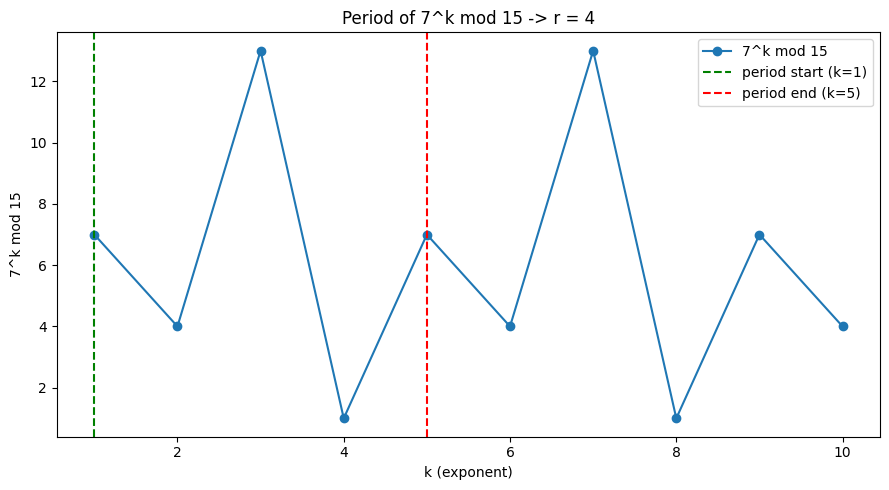

N = 33 -> 3 * 11, x = 28, r = 10
N = 33 -> 11 * 3, x = 14, r = 10
N = 33 -> 3 * 11, x = 19, r = 10


In [18]:
def find_period(x, N):
    """Finds smallest r such that x^r ≡ 1 (mod N)."""
    r, val = 1, x % N
    while val != 1:
        val = (val * x) % N
        r += 1
    return r

def shor(N):
    """Core classical Shor factorization."""
    if N % 2 == 0: return 2, N // 2
    
    while True:
        x = random.randint(2, N - 1)
        g = gcd(x, N)
        if g > 1: return g, N // g
        
        r = find_period(x, N)
        if r % 2 != 0: continue
        
        a = pow(x, r // 2, N)
        if a in (1, N - 1): continue
        
        f1, f2 = gcd(a - 1, N), gcd(a + 1, N)
        if f1 not in (1, N): return f1, N // f1
        if f2 not in (1, N): return f2, N // f2

# Step 2: Test Numbers & Deliverables
numbers = [15, 21, 35, 33, 55, 77, 91, 143, 221, 323, 989]

print("1. FACTORING RESULTS")

for N in numbers:
    f1, f2 = shor(N)
    print(f"N = {N:<4d} -> {f1:>2d} * {f2:<3d} = {N}")

print("\n2. TEN NON-TRIVIAL (N, x, r) TRIPLES")

print(f"{'N':>6} {'x':>6} {'r':>8}")

triples = []
for N in numbers[:10]:
    while True:
        x = random.randint(2, N - 1)
        if gcd(x, N) == 1:
            r = find_period(x, N)
            if r % 2 == 0 and pow(x, r // 2, N) not in (1, N - 1):
                triples.append((N, x, r))
                print(f"{N:>6} {x:>6} {r:>8}")
                break

N_demo, x_demo = 15, 7

r_demo = find_period(x_demo, N_demo)
ks = list(range(1, 2 * r_demo + 3))
vals = [pow(x_demo, k, N_demo) for k in ks]

plt.figure(figsize=(9, 5))
plt.plot(ks, vals, 'o-', label='7^k mod 15')

plt.axvline(1, color='green', linestyle='--', label='period start (k=1)')
plt.axvline(1 + r_demo, color='red', linestyle='--', label=f'period end (k={1 + r_demo})')


plt.xlabel('k (exponent)')
plt.ylabel('7^k mod 15')
plt.title(f'Period of 7^k mod 15 -> r = {r_demo}')

plt.legend()
plt.tight_layout()
plt.show()


def shor_with_info(N):
    """Classical Shor that also returns the chosen x and period r."""
    if N % 2 == 0:
        return 2, N // 2, None, None
    while True:
        x = random.randint(2, N - 1)
        g = gcd(x, N)
        if g > 1:
            return g, N // g, x, 0
        r = find_period(x, N)
        if r % 2 != 0:
            continue
        a = pow(x, r // 2, N)
        if a in (1, N - 1):
            continue
        f1 = gcd(a - 1, N)
        if f1 not in (1, N):
            return f1, N // f1, x, r

f1_33, f2_33, x_33, r_33 = shor_with_info(33)
print(f"N = 33 -> {f1_33} * {f2_33}, x = {x_33}, r = {r_33}")

f1_33, f2_33, x_33, r_33 = shor_with_info(33)
print(f"N = 33 -> {f1_33} * {f2_33}, x = {x_33}, r = {r_33}")

f1_33, f2_33, x_33, r_33 = shor_with_info(33)
print(f"N = 33 -> {f1_33} * {f2_33}, x = {x_33}, r = {r_33}")


 **Quantum Matrix**

 1 & 2: Eigenvalues before and after * r
N = 15, x = 7, n_qubits = 4 (Matrix dim: 16x16)
True period r = 4

Index |   Phase (theta) |       theta * r |   Integer?
    0 |        0.000000 |        0.000000 |          0
    1 |        0.000000 |        0.000000 |          0
    2 |        0.000000 |        0.000000 |          0
    3 |        0.000000 |        0.000000 |          0
    4 |        0.000000 |        0.000000 |          0
    5 |        0.000000 |        0.000000 |          0
    6 |        0.000000 |        0.000000 |          0
    7 |        0.250000 |        1.000000 |          1
    8 |        0.250000 |        1.000000 |          1
    9 |        0.250000 |        1.000000 |          1
   10 |        0.500000 |        2.000000 |          2
   11 |        0.500000 |        2.000000 |          2
   12 |        0.500000 |        2.000000 |          2
   13 |        0.750000 |        3.000000 |          3
   14 |        0.750000 |        3.000000 |          3
   15 |     

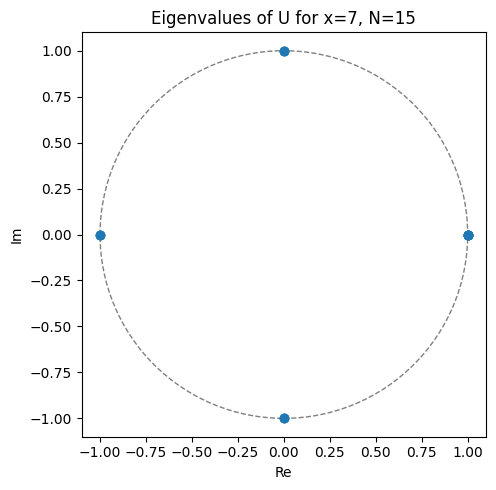

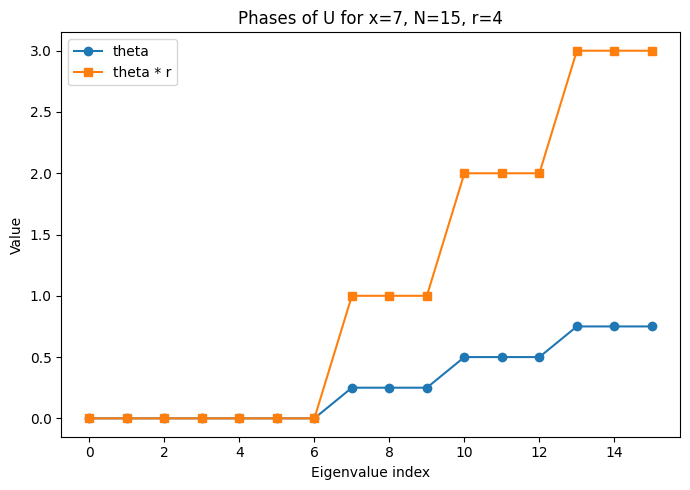

In [19]:
def build_U(x, N):
    """Build the unitary matrix U|j> = |(j*x) mod N> for j<N, |j> for j>=N."""
    n = math.ceil(math.log2(N))
    dim = 2 ** n
    U = np.zeros((dim, dim), dtype=complex)

    for j in range(dim):
        if j < N:
            U[(j * x) % N, j] = 1
        else:
            U[j, j] = 1

    return U

def find_period_from_U(x, N):
    """Find r from the phase of a random eigenvalue of U_{x,N}."""
    U = build_U(x, N)
    eigenvalues = np.linalg.eig(U)[0]

    for _ in range(200):
        lam = random.choice(eigenvalues)
        theta = np.angle(lam) / (2 * np.pi)
        theta = theta % 1.0

        if np.isclose(theta, 0):
            continue

        # Continued fractions via limit_denominator(N)
        frac = Fraction(f"{theta:.8f}").limit_denominator(N)
        s, r = frac.numerator, frac.denominator

        # Failure Mode 2: s and r shared a factor (e.g. 5/10 -> 1/2), r is too small
        if r > 1 and pow(x, r, N) == 1:
            return r, eigenvalues, theta

    return None, eigenvalues, None

# 3. Shor's algorithm using quantum-matrix period finder
def shor_matrix(N):
    """Factor N using U_{x,N} eigenvalues to find the period."""
    if N % 2 == 0:
        return 2, N // 2

    while True:
        x = random.randint(2, N - 1)

        g = gcd(x, N)
        if g > 1:
            return g, N // g

        r, eigenvalues, theta = find_period_from_U(x, N)
        if r is None or r % 2 != 0:
            continue

        a = pow(x, r // 2, N)
        if a in (1, N - 1):
            continue

        f1 = gcd(a - 1, N)
        f2 = gcd(a + 1, N)
        if f1 not in (1, N):
            return f1, N // f1
        if f2 not in (1, N):
            return f2, N // f2


print(" 1 & 2: Eigenvalues before and after * r")

N = 15
x = 7
n_qubits = math.ceil(math.log2(N))

U = build_U(x, N)
eigenvalues = np.linalg.eig(U)[0]

# Compute ground truth period
r_true = 1
val = x % N
while val != 1:
    val = (val * x) % N
    r_true += 1

print(f"N = {N}, x = {x}, n_qubits = {n_qubits} (Matrix dim: {2**n_qubits}x{2**n_qubits})")
print(f"True period r = {r_true}\n")

thetas = [(np.angle(lam) / (2 * np.pi)) % 1.0 for lam in eigenvalues]
thetas_sorted = sorted(thetas)

print(f"{'Index':>5} | {'Phase (theta)':>15} | {'theta * r':>15} | {'Integer?':>10}")

for idx, t in enumerate(thetas_sorted):
    tr = t * r_true
    print(f"{idx:>5} | {t:>15.6f} | {tr:>15.6f} | {round(tr):>10d}")


print("\n  3: Period recovery from a random eigenvalue")


for trial in range(5):
    r, eig, theta = find_period_from_U(x, N)
    print(f"  Trial {trial+1}: theta = {theta:.6f}  ->  r = {r}   {'OK' if r == r_true else 'X'}")


print("\n  4: Factoring using U_{x,N} eigenvalues")

numbers = [15, 21, 35, 33, 55, 77, 91, 143, 221, 323, 989]

for N_val in numbers:
    f1, f2 = shor_matrix(N_val)
    ok = 'OK' if f1 * f2 == N_val else 'X'
    print(f"  N = {N_val:4d}  ->  {f1} * {f2} = {f1 * f2}  {ok}")


# Unit Circle Plot
plt.figure(figsize=(7, 5))
circle = plt.Circle((0, 0), 1, fill=False, color='gray', linestyle='--')
plt.gca().add_patch(circle)
plt.gca().set_aspect('equal')
plt.plot([l.real for l in eigenvalues], [l.imag for l in eigenvalues], 'o')
plt.xlabel('Re')
plt.ylabel('Im')
plt.title(f'Eigenvalues of U for x={x}, N={N}')
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(thetas_sorted, 'o-', label='theta')
plt.plot([t * r_true for t in thetas_sorted], 's-', label='theta * r')
plt.xlabel('Eigenvalue index')
plt.ylabel('Value')
plt.title(f'Phases of U for x={x}, N={N}, r={r_true}')
plt.legend()
plt.tight_layout()
plt.show()


 **Modular Multiplication**

In [20]:
def apply_xyModN(start_wire, num_wires, x, N, input_state):
    """ important
    Applies the gate:
        |y> -> |(x*y) mod N>   if y < N
        |y> -> |y>             if y >= N
    where y is the integer encoded by `num_wires` wires starting at `start_wire`.

    Args:
        start_wire: first wire of the function (least significant bit)
        num_wires : number of wires used to encode y
        x, N      : parameters
        input_state: list of (amplitude, binary_string)
    """
    new_state = []
    for amplitude, binary_rep in input_state:
        # extract the y bits (little-endian: start_wire is LSB)
        y_bits = binary_rep[start_wire : start_wire + num_wires]
        # reverse to make it big-endian for int conversion
        y = int(y_bits[::-1], 2)

        if y < N:
            new_y = (x * y) % N
        else:
            new_y = y

        new_y_bits = format(new_y, f"0{num_wires}b")[::-1]  # little-endian

        new_binary = (
            binary_rep[:start_wire]
            + new_y_bits
            + binary_rep[start_wire + num_wires:]
        )
        new_state.append((amplitude, new_binary))
    return new_state


# 2. Atomic Gate: CxyModN (controlled)
def apply_CxyModN(control_wire, start_wire, num_wires, x, N, input_state):
    """
    Controlled version:
        if control bit == 1: apply xyModN
        else:                leave unchanged
    """
    new_state = []
    for amplitude, binary_rep in input_state:
        if binary_rep[control_wire] == '1':
            # apply xyModN to this basis state
            y_bits = binary_rep[start_wire : start_wire + num_wires]
            y = int(y_bits[::-1], 2)
            new_y = (x * y) % N if y < N else y
            new_y_bits = format(new_y, f"0{num_wires}b")[::-1]
            new_binary = (
                binary_rep[:start_wire]
                + new_y_bits
                + binary_rep[start_wire + num_wires:]
            )
            new_state.append((amplitude, new_binary))
        else:
            new_state.append((amplitude, binary_rep))
    return new_state

print("1. Testing xyModN")
circ1 = "4\nINITSTATE BASIS |1100>\nxyModN 0 4 2 15"
num_wires, parsed = ReadInputString(circ1)
initial = VecToDirac(instantiate_state(parsed, num_wires))
res1 = simulatorS(parsed, initial)
y1 = int(res1[0][1][:4][::-1], 2)
print(f"Input y = 3 -> Output y = {y1}  {'OK' if y1 == 6 else 'X'}")


print("2. Testing CxyModN (Control = |1>)")
circ2 = "5\nINITSTATE BASIS |11001>\nCxyModN 4 0 4 2 15"
num_wires, parsed = ReadInputString(circ2)
initial = VecToDirac(instantiate_state(parsed, num_wires))
res2 = simulatorS(parsed, initial)
y2 = int(res2[0][1][:4][::-1], 2)
ctrl2 = res2[0][1][4]
print(f"Control = {ctrl2}, Output y = {y2}  {'OK' if y2 == 6 and ctrl2 == '1' else 'X'}")


print("\n3. Testing CxyModN (Control = |0>)")
circ3 = "5\nINITSTATE BASIS |11000>\nCxyModN 4 0 4 2 15"
num_wires, parsed = ReadInputString(circ3)
initial = VecToDirac(instantiate_state(parsed, num_wires))
res3 = simulatorS(parsed, initial)
y3 = int(res3[0][1][:4][::-1], 2)
ctrl3 = res3[0][1][4]
print(f"Control = {ctrl3}, Output y = {y3}  {'OK' if y3 == 3 and ctrl3 == '0' else 'X'}")


print("\n 4. Testing CxyModN (Control in Superposition |+>)")
circ4 = "5\nINITSTATE BASIS |11000>\nH 4\nCxyModN 4 0 4 2 15"
num_wires, parsed = ReadInputString(circ4)
initial = VecToDirac(instantiate_state(parsed, num_wires))
res4 = simulatorS(parsed, initial)
for amp, rep in res4:
    y = int(rep[:4][::-1], 2)
    print(f"State |{rep}> (Control={rep[4]}, y={y}) with Amp = {amp:.4f}")


1. Testing xyModN
Input y = 3 -> Output y = 6  OK
2. Testing CxyModN (Control = |1>)
Control = 1, Output y = 6  OK

3. Testing CxyModN (Control = |0>)
Control = 0, Output y = 3  OK

 4. Testing CxyModN (Control in Superposition |+>)
State |11000> (Control=0, y=3) with Amp = 0.7071+0.0000j
State |01101> (Control=1, y=6) with Amp = 0.7071+0.0000j


 **Shors**

Quantum factoring:
N = 15 -> 3 * 5, r: 4

Gate counts and speedup:
N = 15: naive = 271, fast = 24, speedup = 11x


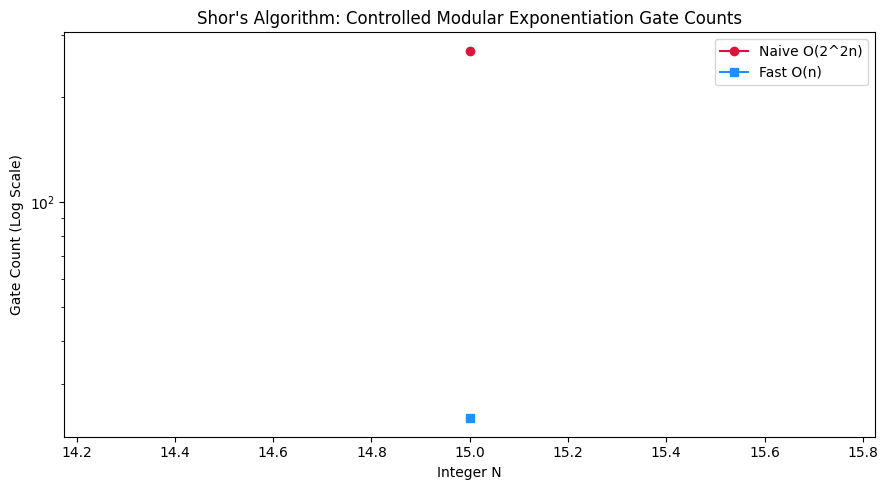

In [22]:
def gates_naive(N):
    n = math.ceil(math.log2(N))
    return (2 ** (2 * n) - 1) + 4 * n

def gates_fast(N):
    n = math.ceil(math.log2(N))
    return 2 * n + 4 * n

def shor_quantum(N):
    if N % 2 == 0:
        return 2, N // 2

    n = math.ceil(math.log2(N))
    num_counting = 2 * n
    total_wires = num_counting + n

    while True:
        x = 7
        g = gcd(x, N)
        if g > 1:
            return g, N // g

        # Assemble circuit instructions
        lines = [str(total_wires), f"INITSTATE BASIS |{'0' * (total_wires - 1)}1>"]
        for w in range(num_counting):
            lines.append(f"H {w}")
        for k in range(num_counting):
            control = num_counting - 1 - k
            mult = pow(x, 2**k, N)
            lines.append(f"CxyModN {control} {num_counting} {n} {mult} {N}")
        lines += generate_phase_estimation_iqft(num_counting)

        nw, parsed = ReadInputString("\n".join(lines))
        compiled = precompile(parsed)

        # Initial state as a Dirac list: |00...01>
        init_state = [(1, format(1, f"0{nw}b"))]

        # Use simulatorS (state-list representation)
        out_state = simulatorS(compiled, init_state)
        out_state = add_duplicate_state(out_state)

        # Partial trace over target register
        counting_probs = np.zeros(2**num_counting, dtype=float)
        for amp, rep in out_state:
            counting_bits = rep[:num_counting]
            counting_idx = int(counting_bits, 2)
            counting_probs[counting_idx] += abs(amp) ** 2

        theta = np.argmax(counting_probs) / (2**num_counting)

        if np.isclose(theta, 0):
            continue

        r = Fraction(theta).limit_denominator(N).denominator
        if r % 2 != 0 or pow(x, r, N) != 1:
            continue

        a = pow(x, r // 2, N)
        if a in (1, N - 1):
            continue

        f1 = gcd(a - 1, N)
        f2 = gcd(a + 1, N)
        if f1 not in (1, N):
            return f1, N // f1, r
        if f2 not in (1, N):
            return f2, N // f2, r

print("Quantum factoring:")
for N in [15]:
    f1, f2, r = shor_quantum(N)
    print(f"N = {N} -> {f1} * {f2}, r: {r}")

print("\nGate counts and speedup:")
for N in [15]:
    gn, gf = gates_naive(N), gates_fast(N)
    print(f"N = {N}: naive = {gn}, fast = {gf}, speedup = {gn/gf:.0f}x")

# Sample values of N
numbers = [15]
naive_counts = [gates_naive(n) for n in numbers]
fast_counts = [gates_fast(n) for n in numbers]

# Plotting
plt.figure(figsize=(9, 5))
plt.plot(numbers, naive_counts, marker='o', label='Naive O(2^2n)', color='crimson')
plt.plot(numbers, fast_counts, marker='s', label='Fast O(n)', color='dodgerblue')

plt.yscale('log')  # Log scale highlights exponential vs polynomial difference
plt.title("Shor's Algorithm: Controlled Modular Exponentiation Gate Counts")
plt.xlabel("Integer N")
plt.ylabel("Gate Count (Log Scale)")
plt.legend()

plt.tight_layout()
plt.show()